# BIST Algorithmic Trading Challenge: Python backtest

CSE 481 Engineering Economics

Yahya Efe Kuruçay, 20220808005

Stocks: AKBNK, ASELS, TUPRS, TCELL, FROTO, EREGL. Backtest period: 1 January 2025 to 1 October 2026. Starting capital: 100,000 TL per stock.

## Strategy

I started from the Dual-Phase Reversal strategy we covered in class and added two things: a second entry for breakouts that have volume behind them, and a trailing stop that gets wider when the stock is trending. The rules and the parameter values are the same for all six stocks.

| Step | Rule |
|---|---|
| Entry A, reversal | RSI(14) crosses back above 30 |
| Entry B, breakout | The close is above the highest high of the previous 20 bars and volume is above its 20-bar average |
| Execution | The signal is calculated on the daily close and the order is filled at the next bar's open |
| Position size | Long only, all available cash, whole shares, no leverage |
| Stop | Chandelier stop: highest high since entry minus k × ATR(14). It only moves up |
| Choosing k | If the Kaufman Efficiency Ratio over 40 bars is above 0.15 the stock is treated as trending and k = 8. Otherwise k = 4.5 |
| Break-even | After the price has gone 3 × ATR above the entry, the stop is raised to at least the entry price |
| End of period | A position that is still open is closed at the last close of the backtest window |

On look-ahead: an indicator value at bar t only uses data up to bar t. The 20-bar high and the volume average are shifted by one bar, so they do not include the current bar. Orders are filled on bar t+1, and the stop that is checked on bar t+1 is set at the close of bar t. I load data from 2024 so the indicators have enough history on the first trading day, but no trade is opened before 1 January 2025.

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

TICKERS = ["AKBNK", "ASELS", "TUPRS", "TCELL", "FROTO", "EREGL"]
BENCHMARK_NET = {"AKBNK": 84_000, "ASELS": 239_000, "TUPRS": 72_000,
                 "TCELL": -18_000, "FROTO": 3_000, "EREGL": 39_000}

START, END = "2025-01-01", "2026-10-01"   # backtest window (inclusive)
WARMUP_START = "2024-01-01"               # indicator warm-up only
INITIAL_CAPITAL = 100_000.0

PARAMS = dict(
    rsi_len=14, rsi_level=30,      # Entry A: RSI crosses back above this level
    breakout_len=20,               # Entry B: close above the previous N-bar high
    vol_len=20, vol_mult=1.0,      # Entry B: volume confirmation
    atr_len=14,                    # ATR for the Chandelier stop
    er_len=40, er_thr=0.15,        # Kaufman Efficiency Ratio regime filter
    k_range=4.5, k_trend=8.0,      # ATR multiple in ranging / trending regime
    breakeven_atr=3.0,             # lift the stop to entry after +3 ATR
)
print("Parameters (identical for all six stocks):")
for k, v in PARAMS.items():
    print(f"  {k:14s} = {v}")

Parameters (identical for all six stocks):
  rsi_len        = 14
  rsi_level      = 30
  breakout_len   = 20
  vol_len        = 20
  vol_mult       = 1.0
  atr_len        = 14
  er_len         = 40
  er_thr         = 0.15
  k_range        = 4.5
  k_trend        = 8.0
  breakeven_atr  = 3.0


## 1. Load historical price data

Daily OHLCV bars from Yahoo Finance (`<TICKER>.IS`). The prices are adjusted for splits but not for dividends. A CSV copy is kept in `data/` so the notebook does not download the data on every run.

In [2]:
def load_prices(ticker):
    path = os.path.join("data", f"{ticker}.csv")
    if os.path.exists(path):
        df = pd.read_csv(path, index_col=0, parse_dates=True)
    else:
        import yfinance as yf
        df = yf.download(f"{ticker}.IS", start=WARMUP_START, end="2026-10-02",
                         auto_adjust=False, progress=False)
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)
        os.makedirs("data", exist_ok=True)
        df.to_csv(path)
    return df[["Open", "High", "Low", "Close", "Volume"]].dropna()

DATA = {t: load_prices(t) for t in TICKERS}

rows = []
for t, df in DATA.items():
    w = df.loc[START:END]
    rows.append({"Stock": t, "Bars (total)": len(df), "Bars (backtest)": len(w),
                 "First bar": w.index[0].date(), "Last bar": w.index[-1].date(),
                 "First open": w.Open.iloc[0], "Last close": w.Close.iloc[-1],
                 "Buy&Hold %": (w.Close.iloc[-1] / w.Open.iloc[0] - 1) * 100})
print(pd.DataFrame(rows).set_index("Stock").to_string())

       Bars (total)  Bars (backtest)   First bar    Last bar  First open  Last close  Buy&Hold %
Stock                                                                                           
AKBNK           690              441  2025-01-02  2026-10-01       65.45       67.55        3.21
ASELS           690              441  2025-01-02  2026-10-01       72.95      370.00      407.20
TUPRS           690              441  2025-01-02  2026-10-01      142.40      387.00      171.77
TCELL           690              441  2025-01-02  2026-10-01       93.20       97.70        4.83
FROTO           691              441  2025-01-02  2026-10-01       94.10       75.45      -19.82
EREGL           691              441  2025-01-02  2026-10-01       24.50       36.62       49.47


## 2. Indicators

In [3]:
def rma(x, n):
    """Wilder's moving average."""
    return x.ewm(alpha=1 / n, adjust=False).mean()

def add_indicators(df, p=PARAMS):
    d = df.copy()
    prev_close = d.Close.shift(1).fillna(d.Close)
    tr = pd.concat([d.High - d.Low, (d.High - prev_close).abs(), (d.Low - prev_close).abs()], axis=1).max(axis=1)
    d["ATR"] = rma(tr, p["atr_len"])

    delta = d.Close.diff().fillna(0)
    gain, loss = delta.clip(lower=0), (-delta).clip(lower=0)
    d["RSI"] = 100 - 100 / (1 + rma(gain, p["rsi_len"]) / rma(loss, p["rsi_len"]).clip(lower=1e-12))

    # shift(1): the breakout level and the volume average exclude the current bar
    d["DonchianHigh"] = d.High.rolling(p["breakout_len"]).max().shift(1)
    d["VolAvg"] = d.Volume.rolling(p["vol_len"]).mean().shift(1)

    # Kaufman Efficiency Ratio: |net move| / sum of |daily moves|, 0 = noise, 1 = straight trend
    n = p["er_len"]
    d["ER"] = (d.Close.diff(n).abs() / d.Close.diff().abs().rolling(n).sum()).fillna(0)
    d["Trending"] = d.ER > p["er_thr"]
    d["K"] = np.where(d.Trending, p["k_trend"], p["k_range"])
    return d

print(add_indicators(DATA["AKBNK"]).loc[START:].head(8).to_string())

            Open  High   Low  Close     Volume  ATR   RSI  DonchianHigh        VolAvg   ER  Trending    K
Date                                                                                                     
2025-01-02 65.45 67.10 64.55  66.20  117926984 2.15 63.42         67.65 72,023,167.40 0.40      True 8.00
2025-01-03 66.35 67.15 65.45  66.20   95587993 2.12 63.42         67.65 74,631,154.75 0.39      True 8.00
2025-01-06 66.35 67.25 66.10  66.80   76614473 2.05 64.98         67.65 76,156,324.20 0.36      True 8.00
2025-01-07 66.75 67.05 64.75  64.75   84326346 2.07 56.18         67.65 73,753,501.80 0.27      True 8.00
2025-01-08 64.80 65.05 63.20  63.60  103420103 2.05 51.93         67.65 73,921,363.50 0.23      True 8.00
2025-01-09 64.05 66.00 63.35  65.90   92848476 2.10 58.67         67.65 76,538,253.50 0.26      True 8.00
2025-01-10 65.95 66.15 63.75  64.40   64530319 2.12 53.41         67.65 73,606,682.05 0.19      True 8.00
2025-01-13 64.35 65.80 62.25  62.80  139456381

## 3. Buy signals

There is no separate sell signal. Every exit comes from the stop, which is handled inside the backtest loop in section 4.

In [4]:
def add_signals(d, p=PARAMS):
    d = d.copy()
    d["SigReversal"] = (d.RSI.shift(1) < p["rsi_level"]) & (d.RSI >= p["rsi_level"])
    d["SigBreakout"] = (d.Close > d.DonchianHigh) & (d.Volume > p["vol_mult"] * d.VolAvg)
    d["Buy"] = d.SigReversal | d.SigBreakout
    return d

rows = []
for t in TICKERS:
    s = add_signals(add_indicators(DATA[t])).loc[START:END]
    rows.append({"Stock": t, "Reversal signals": int(s.SigReversal.sum()),
                 "Breakout signals": int(s.SigBreakout.sum()),
                 "Trending regime % of bars": s.Trending.mean() * 100,
                 "ATR % of price (avg)": (s.ATR / s.Close).mean() * 100})
print(pd.DataFrame(rows).set_index("Stock").to_string())

       Reversal signals  Breakout signals  Trending regime % of bars  ATR % of price (avg)
Stock                                                                                     
AKBNK                 7                24                      55.78                  3.56
ASELS                 1                44                      62.36                  3.84
TUPRS                 2                32                      57.60                  3.07
TCELL                 1                21                      29.93                  3.07
FROTO                 3                23                      54.20                  3.08
EREGL                 5                30                      53.74                  3.04


## 4. Backtest: position sizing and risk management

In [5]:
def backtest(df, p=PARAMS, capital=INITIAL_CAPITAL):
    d = add_signals(add_indicators(df, p), p)
    o, h, l, c = d.Open.values, d.High.values, d.Low.values, d.Close.values
    atr, K, buy, rev = d.ATR.values, d.K.values, d.Buy.values, d.SigReversal.values
    idx = d.index
    first = idx.searchsorted(pd.Timestamp(START))
    last = idx.searchsorted(pd.Timestamp(END), side="right") - 1

    cash, shares, pending = capital, 0, None
    trades, equity = [], []
    stop_line = np.full(len(d), np.nan)

    def close_trade(i, price, why):
        nonlocal cash, shares
        cash += shares * price
        pnl = shares * (price - entry_price)
        trades.append({"Entry Date": idx[entry_i].date(), "Entry Signal": entry_why, "Entry Price": entry_price,
                       "Exit Date": idx[i].date(), "Exit Price": price, "Exit Reason": why, "Shares": shares,
                       "Bars Held": i - entry_i, "PnL (TL)": pnl, "PnL (%)": (price / entry_price - 1) * 100,
                       "Equity After": cash})
        shares = 0

    for i in range(first, last + 1):
        # 1) fill the order created by yesterday's close signal at today's open
        if shares == 0 and pending:
            shares = int(cash // o[i])                     # all-in, whole shares
            cash -= shares * o[i]
            entry_price, entry_i, entry_why = o[i], i, pending
            entry_atr = atr[i - 1]
            stop = entry_price - K[i - 1] * atr[i - 1]     # initial ATR stop, known before the open
            highest = entry_price
        pending = None

        # 2) risk management: stop fixed at the previous close is checked against today's bar
        if shares:
            stop_line[i] = stop
            label = "Break-even stop" if stop == entry_price else "Chandelier stop"
            if i > entry_i and o[i] <= stop:
                close_trade(i, o[i], label + " (gap open)")
            elif l[i] <= stop:
                close_trade(i, stop, label)

        # 3) after the close: trail the stop for tomorrow, or look for a new entry
        if shares:
            highest = max(highest, h[i])
            stop = max(stop, highest - K[i] * atr[i])
            if highest >= entry_price + p["breakeven_atr"] * entry_atr:
                stop = max(stop, entry_price)
        elif buy[i] and i < last:
            pending = "RSI reversal" if rev[i] else "Volume breakout"

        equity.append(cash + shares * c[i])

    if shares:
        close_trade(last, c[last], "End of backtest")

    equity = pd.Series(equity, index=idx[first:last + 1], name="Equity")
    stops = pd.Series(stop_line, index=idx).loc[idx[first]:idx[last]]
    return pd.DataFrame(trades), equity, stops, d.loc[idx[first]:idx[last]]

RESULTS = {t: backtest(DATA[t]) for t in TICKERS}
print("Backtest finished for:", ", ".join(RESULTS))

Backtest finished for: AKBNK, ASELS, TUPRS, TCELL, FROTO, EREGL


## 5. Trade log

Every buy and sell with its date, exact price, share count and profit or loss.

In [6]:
for t in TICKERS:
    trades = RESULTS[t][0]
    log = trades.copy()
    log.index = np.arange(1, len(log) + 1); log.index.name = "#"
    print("=" * 150)
    print(f"{t}  |  completed trades: {len(log)}  |  net profit: {log['PnL (TL)'].sum():+,.0f} TL")
    print("=" * 150)
    print(log.to_string())
    print()

AKBNK  |  completed trades: 6  |  net profit: +102,967 TL
   Entry Date     Entry Signal  Entry Price   Exit Date  Exit Price                 Exit Reason  Shares  Bars Held  PnL (TL)  PnL (%)  Equity After
#                                                                                                                                                  
1  2025-01-22  Volume breakout        68.60  2025-03-19       68.00  Break-even stop (gap open)    1457         40   -874.20    -0.87     99,125.80
2  2025-03-26     RSI reversal        54.50  2025-09-02       64.69             Chandelier stop    1818        106 18,530.14    18.70    117,655.94
3  2025-10-17     RSI reversal        54.95  2026-03-06       77.50             Chandelier stop    2141         98 48,281.96    41.04    165,937.90
4  2026-04-02     RSI reversal        66.65  2026-05-04       71.03             Chandelier stop    2489         20 10,901.30     6.57    176,839.20
5  2026-05-25     RSI reversal        64.20  2026-07-0

## 6. Performance metrics

A trade that closes exactly at its entry price (break-even stop) is counted separately, as neither a win nor a loss. Win rate is winning trades divided by all trades.

In [7]:
def metrics(trades, equity, capital=INITIAL_CAPITAL):
    pnl = trades["PnL (TL)"]
    wins, losses, flat = pnl[pnl > 0], pnl[pnl < 0], pnl[pnl == 0]
    curve = pd.concat([pd.Series([capital]), equity.reset_index(drop=True)], ignore_index=True)
    dd = curve / curve.cummax() - 1
    return {
        "Net Profit (TL)": pnl.sum(),
        "Final Capital (TL)": capital + pnl.sum(),
        "Total Trades": len(trades),
        "Winning Trades": len(wins),
        "Losing Trades": len(losses),
        "Break-even Trades": len(flat),
        "Win Rate (%)": 100 * len(wins) / len(trades),
        "Max Drawdown (%)": dd.min() * 100,
        "Max Drawdown (TL)": (curve - curve.cummax()).min(),
        "Profit Factor": wins.sum() / abs(losses.sum()) if losses.sum() != 0 else np.inf,
        "Average Trade (TL)": pnl.mean(),
        "Average Trade (%)": trades["PnL (%)"].mean(),
    }

METRICS = pd.DataFrame({t: metrics(RESULTS[t][0], RESULTS[t][1]) for t in TICKERS}).T
for col in ["Total Trades", "Winning Trades", "Losing Trades", "Break-even Trades"]:
    METRICS[col] = METRICS[col].astype(int)
num = lambda x: f"{x:,.0f}" if float(x).is_integer() else f"{x:,.2f}"
print(METRICS.T.to_string(float_format=num))

                        AKBNK       ASELS      TUPRS      TCELL      FROTO      EREGL
Net Profit (TL)    102,967.46  263,818.25 120,988.26  -5,561.26  14,163.98  66,787.23
Final Capital (TL) 202,967.46  363,818.25 220,988.26  94,438.74 114,163.98 166,787.23
Total Trades                6           4          5          5          6          5
Winning Trades              5           3          4          2          2          4
Losing Trades               1           1          1          2          2          0
Break-even Trades           0           0          0          1          2          1
Win Rate (%)            83.33          75         80         40      33.33         80
Max Drawdown (%)       -19.41      -25.15     -17.39     -18.92     -26.20     -17.64
Max Drawdown (TL)  -33,076.03 -122,268.03 -29,731.16 -22,042.80 -39,880.15 -26,698.31
Profit Factor          118.79        6.16      21.04       0.52       2.41        inf
Average Trade (TL)  17,161.24   65,954.56  24,197.65  

## 7. Benchmark comparison

A stock passes only if its final capital is higher than its own benchmark final capital.

In [8]:
rows = []
for t in TICKERS:
    net = METRICS.loc[t, "Net Profit (TL)"]
    bench = BENCHMARK_NET[t]
    rows.append({"Stock": t,
                 "Benchmark Net (TL)": bench, "Strategy Net (TL)": net,
                 "Benchmark Final (TL)": INITIAL_CAPITAL + bench, "Strategy Final (TL)": INITIAL_CAPITAL + net,
                 "Difference (TL)": net - bench,
                 "Trades": int(METRICS.loc[t, "Total Trades"]),
                 "Result": "PASS" if net > bench else "FAIL"})
COMPARE = pd.DataFrame(rows).set_index("Stock")
pd.set_option("display.float_format", lambda x: f"{x:,.0f}")
print(COMPARE.to_string())
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print()
print(f"Stocks beating their benchmark : {(COMPARE.Result == 'PASS').sum()} / {len(COMPARE)}")
print(f"Minimum completed trades       : {COMPARE.Trades.min()} (requirement: at least 3)")
print("CHALLENGE", "PASSED" if (COMPARE.Result == "PASS").all() and COMPARE.Trades.min() >= 3 else "NOT PASSED")

       Benchmark Net (TL)  Strategy Net (TL)  Benchmark Final (TL)  Strategy Final (TL)  Difference (TL)  Trades Result
Stock                                                                                                                  
AKBNK               84000            102,967               184,000              202,967           18,967       6   PASS
ASELS              239000            263,818               339,000              363,818           24,818       4   PASS
TUPRS               72000            120,988               172,000              220,988           48,988       5   PASS
TCELL              -18000             -5,561                82,000               94,439           12,439       5   PASS
FROTO                3000             14,164               103,000              114,164           11,164       6   PASS
EREGL               39000             66,787               139,000              166,787           27,787       5   PASS

Stocks beating their benchmark : 6 / 6


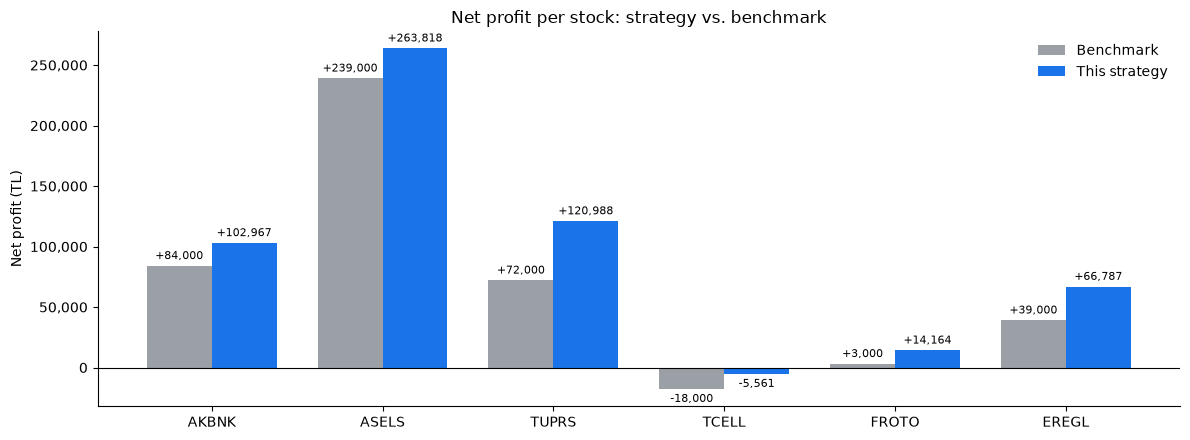

In [9]:
fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(len(TICKERS)); w = 0.38
b1 = ax.bar(x - w / 2, COMPARE["Benchmark Net (TL)"], w, label="Benchmark", color="#9aa0a6")
b2 = ax.bar(x + w / 2, COMPARE["Strategy Net (TL)"], w, label="This strategy", color="#1a73e8")
for bars in (b1, b2):
    for b in bars:
        v = b.get_height()
        ax.annotate(f"{v:+,.0f}", (b.get_x() + b.get_width() / 2, v), ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=8, xytext=(0, 3 if v >= 0 else -3),
                    textcoords="offset points")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(TICKERS)
ax.set_ylabel("Net profit (TL)"); ax.set_title("Net profit per stock: strategy vs. benchmark")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 8. Trade charts

One figure per stock. The top panel is the price with the stop line, the buy (▲) and sell (▼) points at the fill prices, and the result of each trade. The middle panel is the profit or loss of each trade. The bottom panel is the equity curve, with the starting capital and the benchmark final capital drawn as horizontal lines.

In [10]:
GREEN, RED, GREY = "#1e8e3e", "#d93025", "#5f6368"
trade_color = lambda v: GREEN if v > 0 else RED if v < 0 else GREY

def plot_stock(t):
    trades, equity, stops, d = RESULTS[t]
    fig, (ax, axp, axe) = plt.subplots(3, 1, figsize=(15, 12), gridspec_kw={"height_ratios": [3.2, 1.2, 1.3]})

    ax.plot(d.index, d.Close, color="#3c4043", lw=1.1, label="Close")
    ax.plot(stops.index, stops.values, color=RED, lw=1.0, ls="--", drawstyle="steps-post", label="Chandelier stop")
    span = d.Close.max() - d.Close.min()
    for n, tr in trades.iterrows():
        e, x = pd.Timestamp(tr["Entry Date"]), pd.Timestamp(tr["Exit Date"])
        col = trade_color(tr["PnL (TL)"])
        ax.axvspan(e, x, color=col, alpha=0.08, lw=0)
        ax.plot([e, x], [tr["Entry Price"], tr["Exit Price"]], color=col, lw=1.2, alpha=0.8)
        ax.scatter(e, tr["Entry Price"], marker="^", s=130, color=GREEN, edgecolor="black", zorder=5)
        ax.scatter(x, tr["Exit Price"], marker="v", s=130, color=RED, edgecolor="black", zorder=5)
        box = dict(boxstyle="round,pad=0.25", fc="white", alpha=0.92, lw=0.7)
        ax.annotate(f"#{n + 1} BUY {tr['Entry Price']:.2f}\n{tr['Entry Date']:%d.%m.%y}, {tr['Shares']:,} sh",
                    (e, tr["Entry Price"]), xytext=(0, -38 - 30 * (n % 2)), textcoords="offset points",
                    ha="center", fontsize=7.5, color=GREEN, bbox={**box, "ec": GREEN},
                    arrowprops=dict(arrowstyle="-", color=GREEN, lw=0.6))
        ax.annotate(f"#{n + 1} SELL {tr['Exit Price']:.2f}\n{tr['Exit Date']:%d.%m.%y}\n{tr['PnL (TL)']:+,.0f} TL ({tr['PnL (%)']:+.1f}%)",
                    (x, tr["Exit Price"]), xytext=(0, 22 + 44 * (n % 2)), textcoords="offset points",
                    ha="center", fontsize=7.5, color=col, fontweight="bold", bbox={**box, "ec": col},
                    arrowprops=dict(arrowstyle="-", color=col, lw=0.6))
    ax.set_ylim(d.Close.min() - 0.28 * span, d.Close.max() + 0.30 * span)
    net = trades["PnL (TL)"].sum()
    ax.set_title(f"{t}: {len(trades)} trades, net {net:+,.0f} TL, final {INITIAL_CAPITAL + net:,.0f} TL "
                 f"(benchmark {INITIAL_CAPITAL + BENCHMARK_NET[t]:,.0f} TL)", fontsize=12, fontweight="bold")
    ax.set_ylabel("Price (TL)"); ax.legend(loc="upper left", frameon=False, fontsize=8)

    labels = [f"#{n + 1}\n{tr['Entry Date']:%d.%m.%y}→{tr['Exit Date']:%d.%m.%y}" for n, tr in trades.iterrows()]
    bars = axp.bar(labels, trades["PnL (TL)"], color=[trade_color(v) for v in trades["PnL (TL)"]])
    for b, (_, tr) in zip(bars, trades.iterrows()):
        v = tr["PnL (TL)"]
        axp.annotate(f"{v:+,.0f} TL\n{tr['PnL (%)']:+.1f}%", (b.get_x() + b.get_width() / 2, v), ha="center",
                     va="bottom" if v >= 0 else "top", fontsize=8, xytext=(0, 3 if v >= 0 else -3),
                     textcoords="offset points")
    axp.axhline(0, color="black", lw=0.8); axp.margins(y=0.35)
    axp.set_ylabel("Trade P/L (TL)"); axp.set_title("Profit / loss of each completed trade", fontsize=10)
    axp.tick_params(axis="x", labelsize=8)

    axe.plot(equity.index, equity.values, color="#1a73e8", lw=1.4, label="Strategy equity")
    axe.axhline(INITIAL_CAPITAL, color="#9aa0a6", lw=0.9, ls=":", label="Initial capital")
    axe.axhline(INITIAL_CAPITAL + BENCHMARK_NET[t], color="#e37400", lw=1.0, ls="--", label="Benchmark final capital")
    axe.set_ylabel("Equity (TL)"); axe.set_title("Equity curve (marked to market daily)", fontsize=10)
    axe.legend(loc="upper left", frameon=False, fontsize=8)

    for a in (ax, axe):
        a.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); a.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
        a.set_xlim(d.index[0] - pd.Timedelta(days=10), d.index[-1] + pd.Timedelta(days=10))
    for a in (ax, axp, axe):
        a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
        a.spines[["top", "right"]].set_visible(False); a.grid(axis="y", alpha=0.25)
    plt.tight_layout(); plt.show()

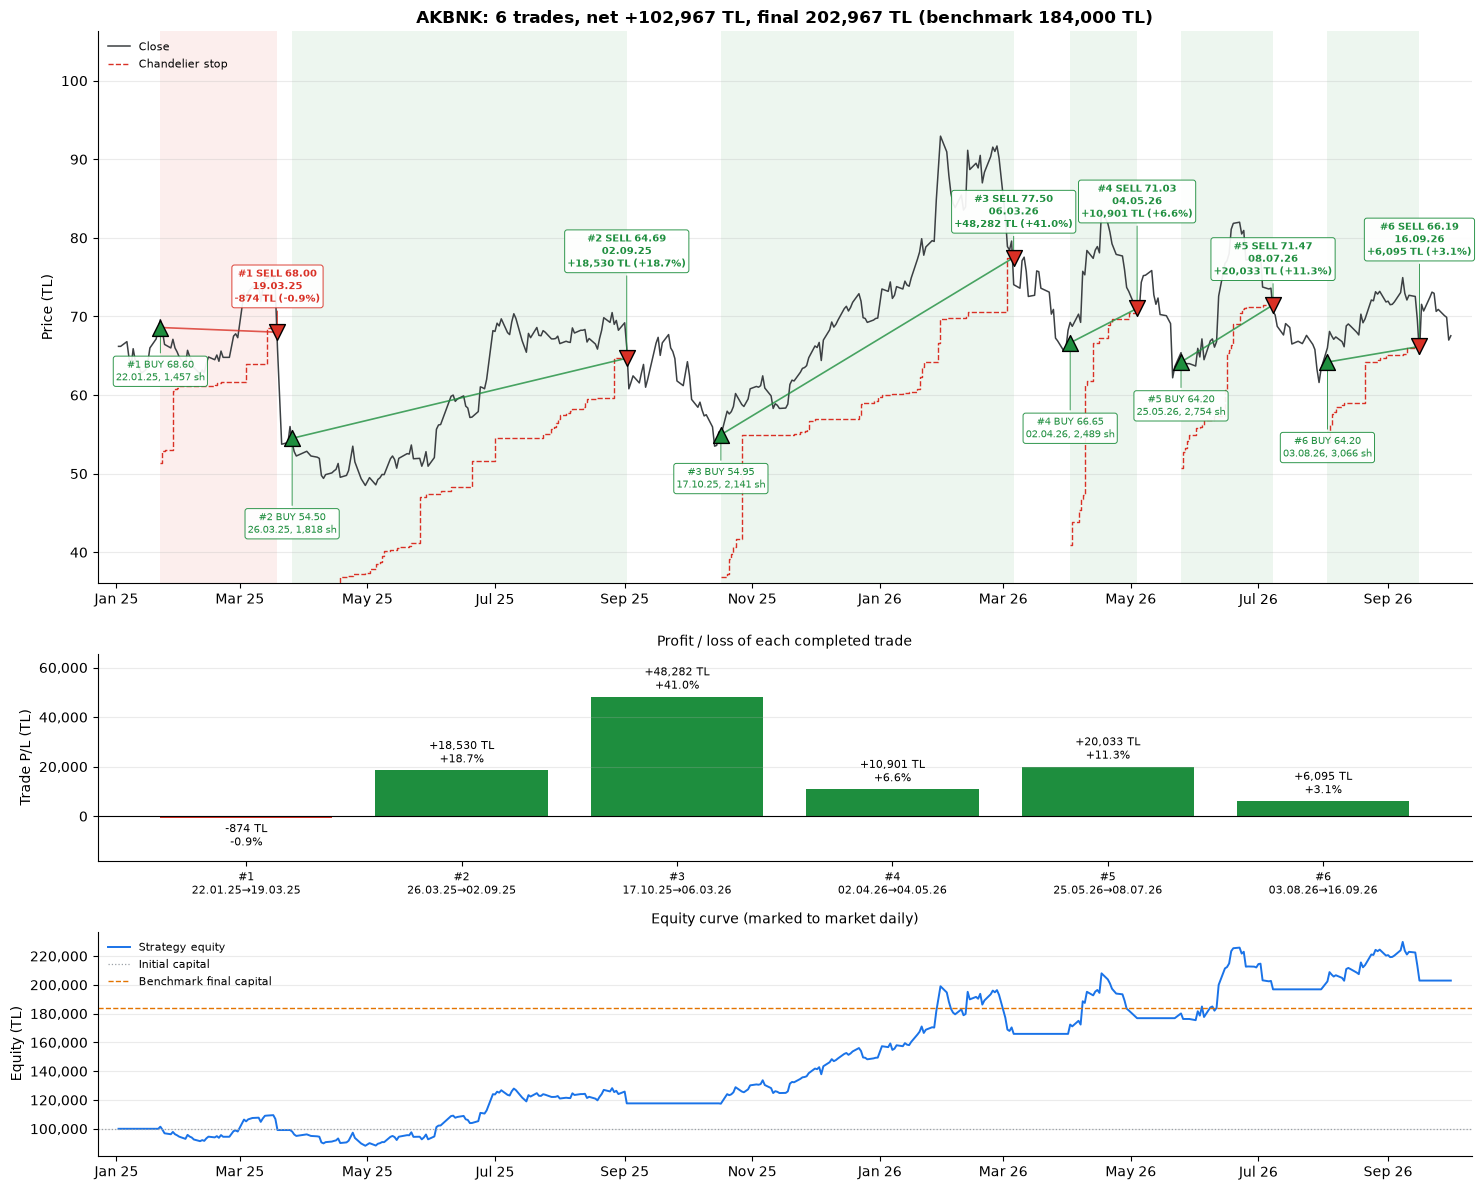

In [11]:
plot_stock("AKBNK")

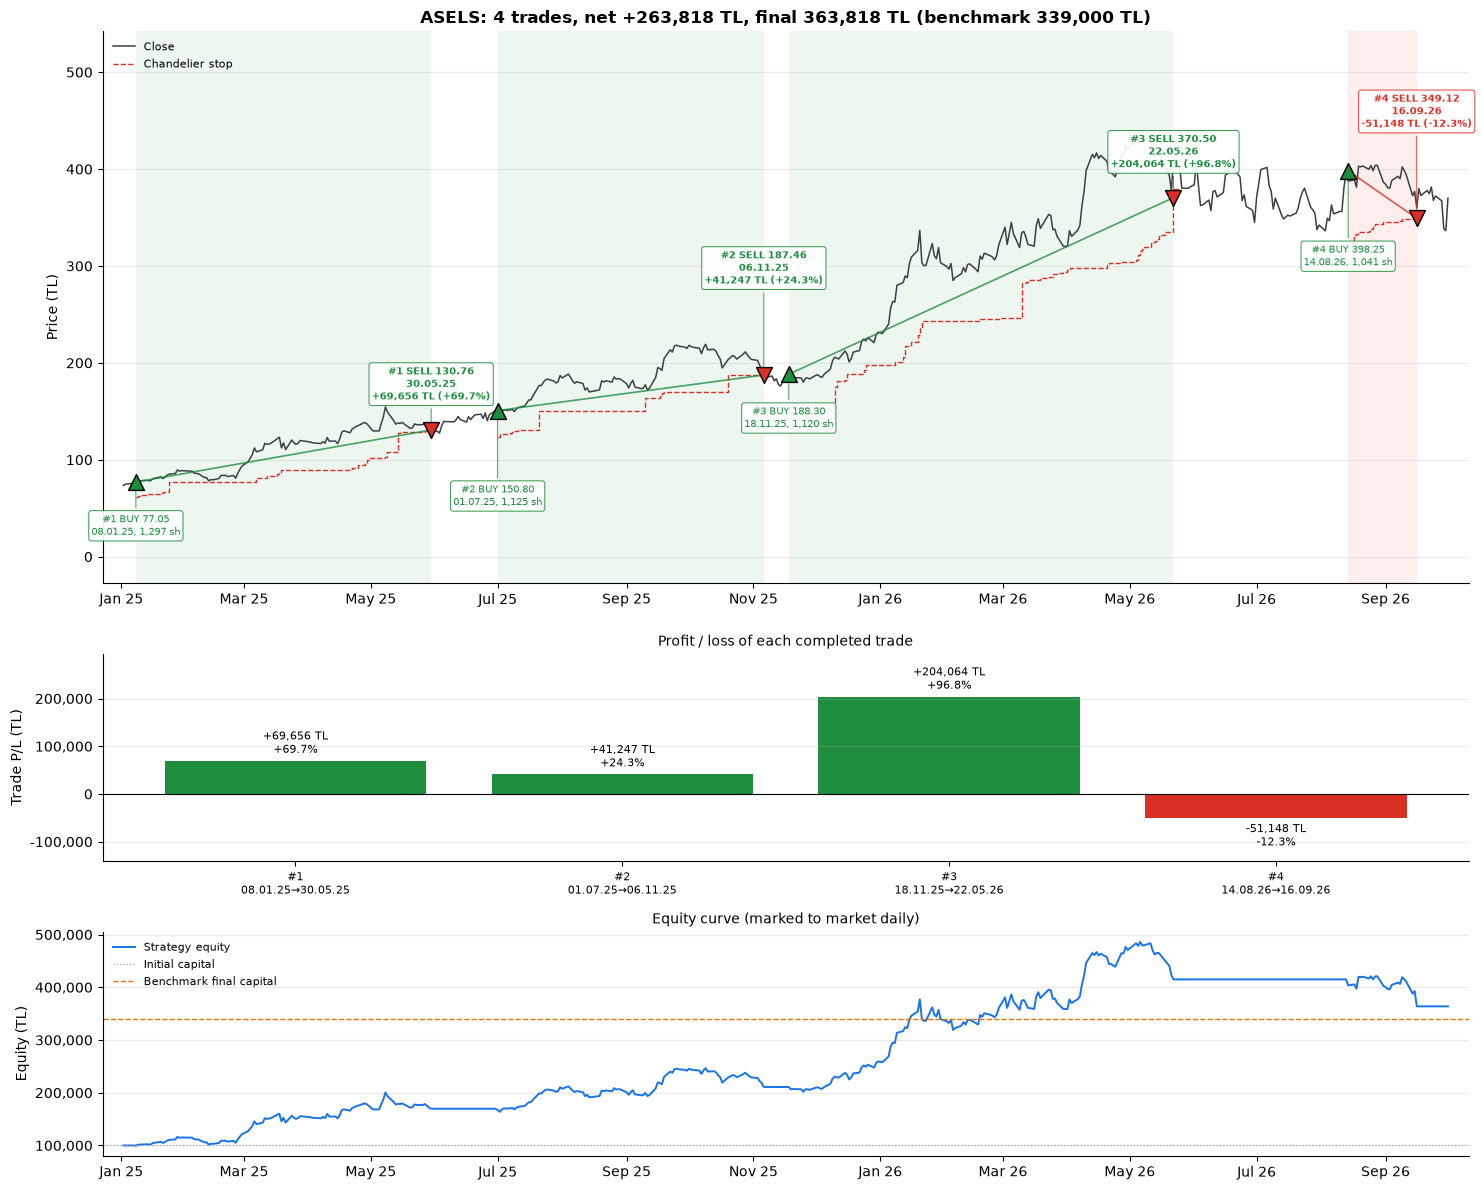

In [12]:
plot_stock("ASELS")

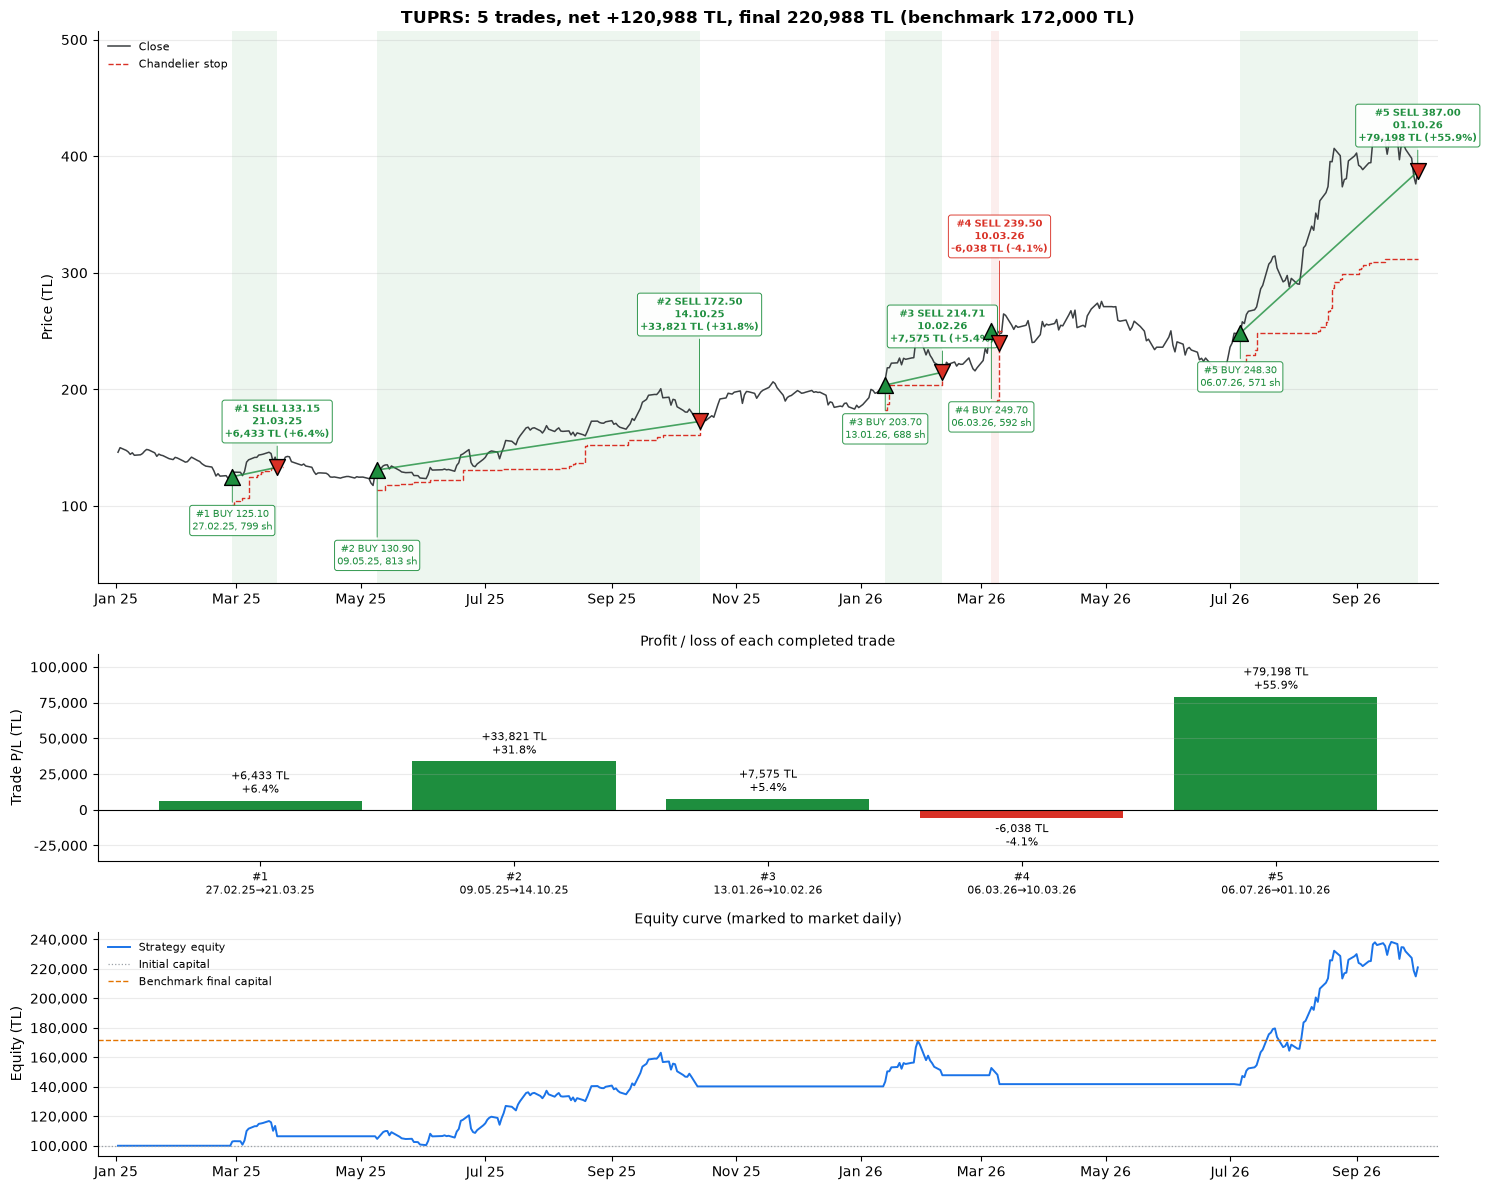

In [13]:
plot_stock("TUPRS")

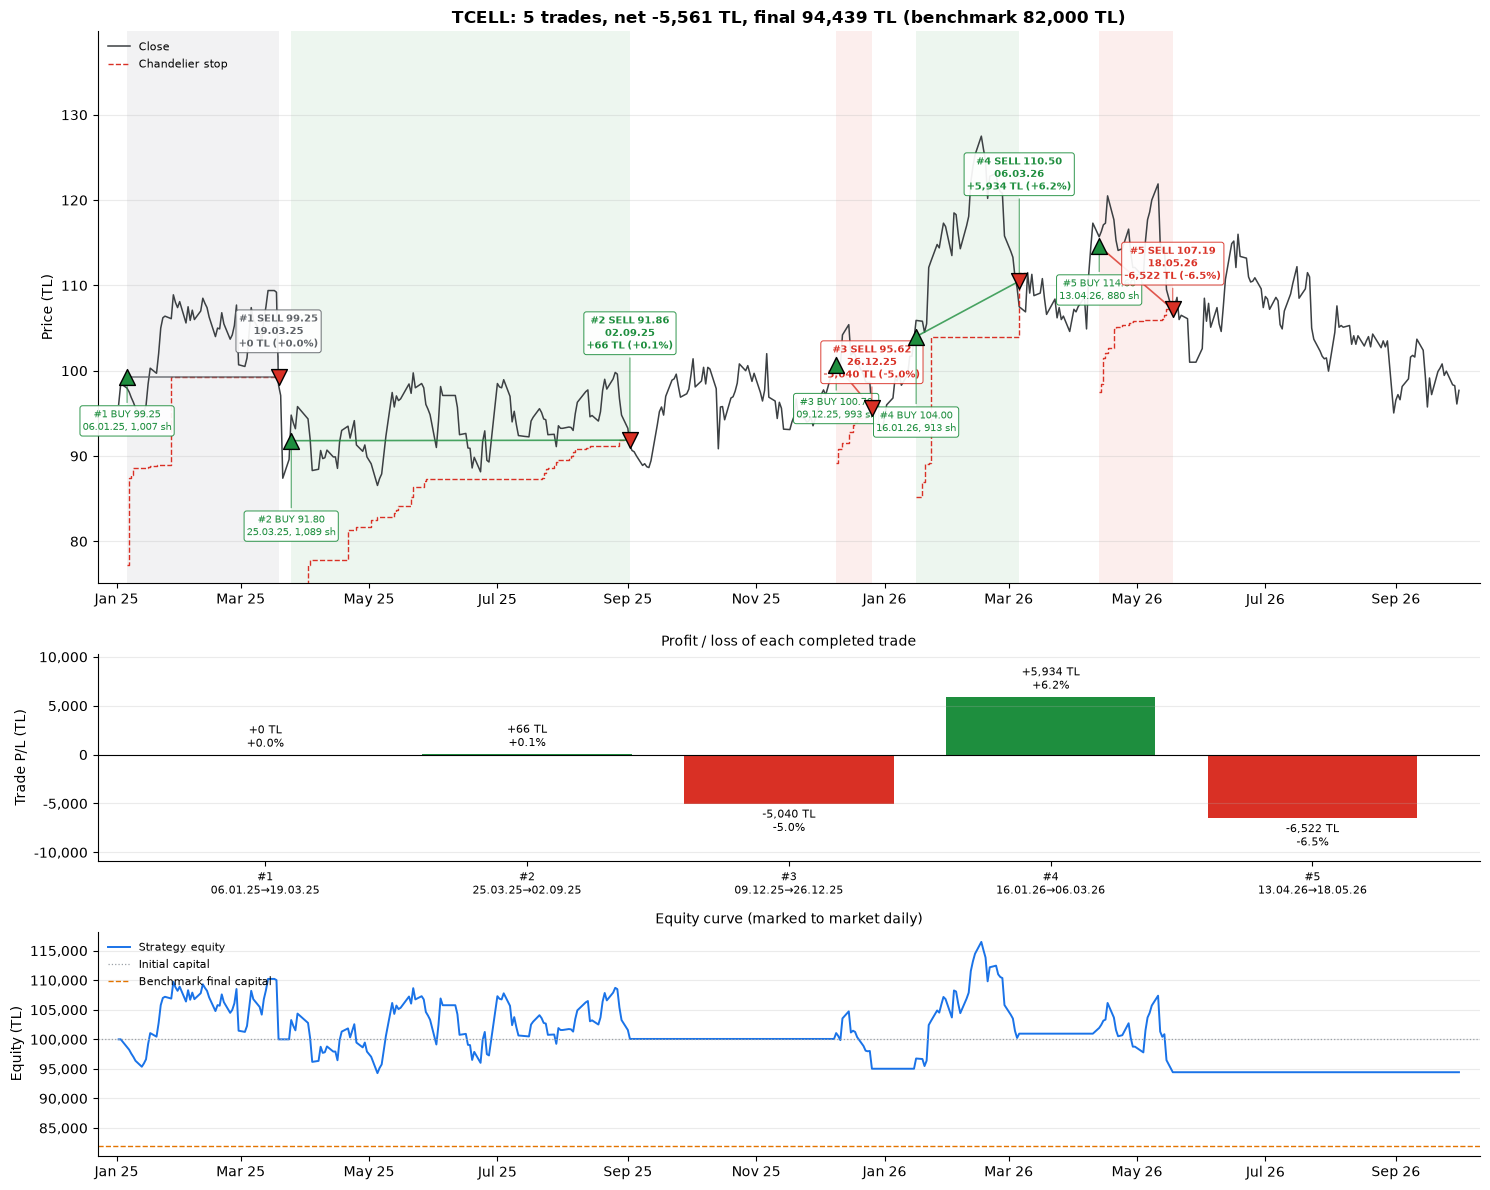

In [14]:
plot_stock("TCELL")

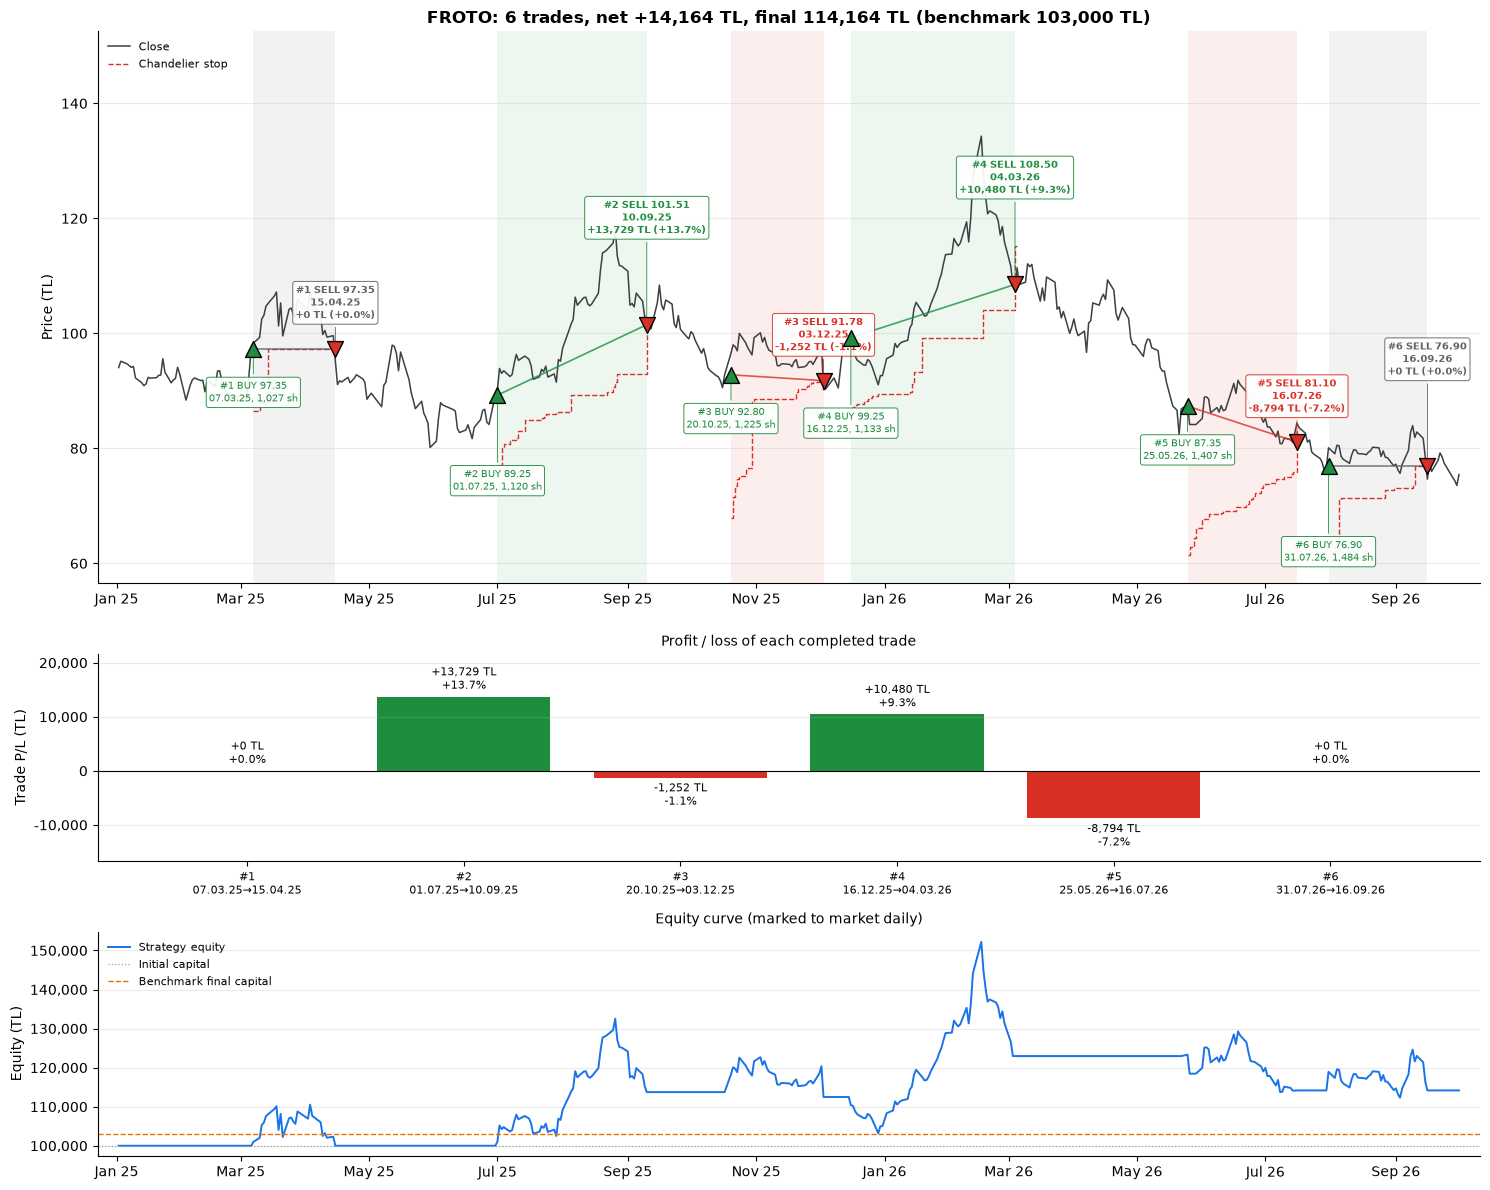

In [15]:
plot_stock("FROTO")

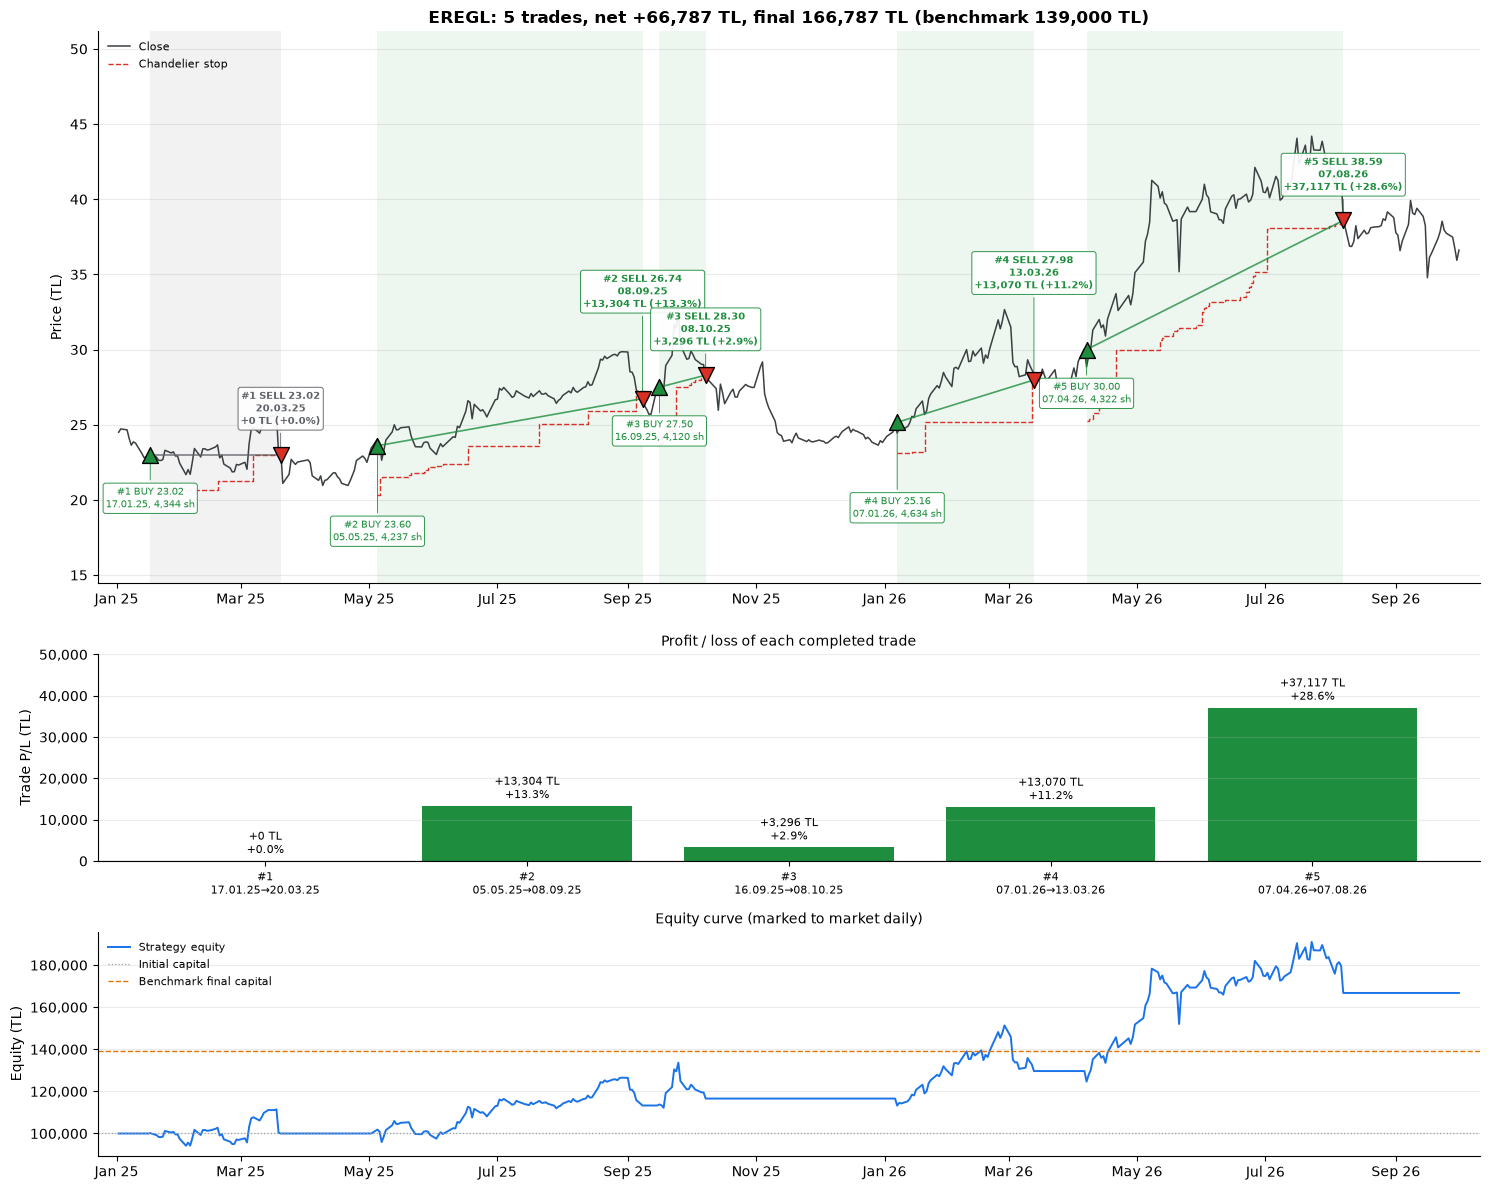

In [16]:
plot_stock("EREGL")

## 9. Numbers used in the final analysis

In [17]:
rows = []
for t in TICKERS:
    trades, equity, stops, d = RESULTS[t]
    stops_hit = trades["Exit Reason"].str.contains("stop")
    rows.append({
        "Stock": t,
        "Buy&Hold (%)": (d.Close.iloc[-1] / d.Open.iloc[0] - 1) * 100,
        "Strategy (%)": trades["PnL (TL)"].sum() / INITIAL_CAPITAL * 100,
        "Trending bars (%)": d.Trending.mean() * 100,
        "Avg ATR/price (%)": (d.ATR / d.Close).mean() * 100,
        "Time in market (%)": trades["Bars Held"].sum() / len(d) * 100,
        "Stop exits": int(stops_hit.sum()),
        "Losing stop exits": int((stops_hit & (trades["PnL (TL)"] < 0)).sum()),
        "Break-even stop exits": int((stops_hit & (trades["PnL (TL)"] == 0)).sum()),
        "Reversal entries": int((trades["Entry Signal"] == "RSI reversal").sum()),
        "Breakout entries": int((trades["Entry Signal"] == "Volume breakout").sum()),
        "Best trade (%)": trades["PnL (%)"].max(),
        "Worst trade (%)": trades["PnL (%)"].min(),
    })
print(pd.DataFrame(rows).set_index("Stock").T.to_string(float_format=num))

Stock                  AKBNK  ASELS  TUPRS  TCELL  FROTO  EREGL
Buy&Hold (%)            3.21 407.20 171.77   4.83 -19.82  49.47
Strategy (%)          102.97 263.82 120.99  -5.56  14.16  66.79
Trending bars (%)      55.78  62.36  57.60  29.93  54.20  53.74
Avg ATR/price (%)       3.56   3.84   3.07   3.07   3.08   3.04
Time in market (%)     74.38  76.64  47.17  52.15  52.38  62.81
Stop exits                 6      4      4      5      6      5
Losing stop exits          1      1      1      2      2      0
Break-even stop exits      0      0      0      1      2      1
Reversal entries           5      1      2      1      3      2
Breakout entries           1      3      3      4      3      3
Best trade (%)         41.04  96.76  55.86   6.25  13.73  28.63
Worst trade (%)        -0.87 -12.34  -4.08  -6.47  -7.16      0


## 10. Final analysis: why did the same strategy perform differently across the six stocks?

The rules and parameters were identical for every stock, but the net result goes from +263,818 TL on ASELS to -5,561 TL on TCELL. The reason is that the six stocks behaved very differently during this period.

| Stock | Buy and hold | Strategy | How the stock moved | What happened to the strategy |
|---|---|---|---|---|
| ASELS | +407% | +264% | Strong uptrend for most of the period (62% of bars trending) | Stayed in the trend, but lost ground each time it was stopped out and had to buy back higher |
| TUPRS | +172% | +121% | Long flat stretches, then sharp rallies | Caught the two big rallies and was in the market only 47% of the time |
| AKBNK | +3% | +103% | Moved between about 49 and 93 TL and ended near where it started | Bought five oversold reversals and sold all five at a higher price |
| EREGL | +49% | +67% | Slow, steady uptrend with low volatility | Four winning trades and no losing trade |
| FROTO | -20% | +14% | Rallies inside a larger downtrend | Two winning trades, four closed flat or at a loss |
| TCELL | +5% | -6% | Sideways and choppy (only 30% of bars trending) | Breakouts kept failing, but the losses stayed small |

### Trending and sideways markets

The Efficiency Ratio filter marked 62% of ASELS bars as trending and only 30% of TCELL bars. When a stock trends, the wide stop (8 × ATR) keeps the position open through normal pullbacks. One ASELS trade ran from 188.30 to 370.50 (+96.8%), and the last TUPRS trade was still open at the end of the period with +55.9%. A sideways stock never moves far enough for the stop to lock in much, and the best TCELL trade made only +6.3%.

### Momentum strength

The strategy is long only and exits on a trailing stop, so its profit is limited by how far the stock actually runs. ASELS and TUPRS had the strongest momentum and gave the largest profits in TL. Even so, the strategy made less than buy and hold on both, because it was out of the market for part of the rise. On ASELS it sold at 130.76 and bought back at 150.80. On TUPRS it sold at 172.50 and bought back at 203.70. That is the cost of using a trailing stop in a strong trend.

### Reversal behaviour

AKBNK is where the strategy did best compared to buy and hold: 103% against 3%. The stock sold off hard several times and recovered each time. Five of its six trades were RSI reversal entries, at 54.50, 54.95, 66.65, 64.20 and 64.20, and the stop closed each one at a higher price. FROTO also gave reversal entries in 2026, but the stock was falling and the bounces were weak. One of those trades lost 7.2% and another closed at break-even.

### False breakouts

Four of the five TCELL entries were volume breakouts. Two of them turned around within a few weeks and lost 5.0% and 6.5%. ASELS had one as well, near the top: it bought at 398.25 and was stopped at 349.12 for -12.3%. At -51,148 TL that is the biggest single loss in the whole test. Breakout entries made money when the move continued, but five of the seven losing trades in the test were breakout entries.

### Volatility

AKBNK and ASELS were the most volatile, with an average ATR of 3.6% and 3.8% of price. The other four were all between 3.0% and 3.1%. More volatility gives bigger swings to trade, but the stop also sits further away. ASELS had a maximum drawdown of -25.2%, while AKBNK, TUPRS, TCELL and EREGL were between -17% and -19%. FROTO had the deepest one at -26.2% for a different reason: it spiked to about 134 TL, fell back, and gapped through the stop, so the trade closed at 108.50.

### Volume

The breakout entry needs volume above its 20-day average. ASELS gave 44 breakout signals with that confirmation and EREGL 30, compared with 21 for TCELL and 23 for FROTO. That is what I would expect, since a stock in a strong uptrend makes new highs more often. The volume filter did not save TCELL: three of its four breakout trades did not make money.

### How often the stop was hit

30 of the 31 trades ended at the stop. The only exception is the last TUPRS trade, which was closed by the end-of-period rule. Of the 30 stop exits, 19 were profitable because the stop had already moved above the entry price, 4 closed exactly at break-even, and 7 were losses. In nine cases the price opened below the stop and the trade was filled at the open, for example AKBNK on 19 March 2025. On AKBNK (5 of 6), EREGL (4 of 5) and TUPRS (3 of 4) most stop exits were profitable, so the stop mainly worked as a way to take profit. On TCELL and FROTO it mostly limited losses, which is why TCELL ended slightly below the starting capital and FROTO only 14% above it.

### Benchmark result

The strategy finished above the benchmark on all six stocks. The margin is smallest on FROTO (+11,164 TL) and TCELL (+12,439 TL), the two stocks that did not have a lasting uptrend in this period.

### Limitations

- I chose the parameter values with a grid search over the same 2025-2026 period and used one set for all six stocks. I tried several entry types (breakout, moving average cross, RSI, volume spike, Bollinger) with different ATR stop multiples, and kept the setting where the weakest stock had the largest margin over its benchmark while every stock still had at least 4 trades. The trading rules do not use future data, but the parameters were fitted to this period, so I would expect smaller margins on new data. I did not test the strategy on a separate period.
- Commission and slippage are not included. A stop is assumed to fill exactly at the stop price unless the bar opens below it.
- The prices are Yahoo Finance daily bars adjusted for splits but not for dividends, so dividends are not part of the profit figures.
- The TUPRS result depends on its last trade, which was still open at the end and was closed at the 1 October 2026 close (+79,198 TL).